<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Introduction to Regularization - Solution

---

## 1. The Cost Function and The Penalty
To understand how we actually constrain these weights and prevent overfitting, we need to look at how a model learns.

During training, a model's entire goal is to find the coefficients that minimize its total error. Think of a **Cost Function** _(or Loss Function)_ as the model's scorecard. Just like in golf, a lower score is better. The model calculates the difference between its predictions and the actual truth, and then searches for the exact coefficients that bring this scorecard as close to zero as possible.

In standard Linear Regression, the cost function only cares about minimizing that prediction error:
> `Cost = Sum of Squared Errors (Loss)`

**Regularization** changes the rules of the game by adding a **"penalty"** term to this scorecard. Now, the model is forced to balance two competing goals: minimize the prediction error and keep the coefficients small.
> `Regularized Cost = Loss + Penalty based on coefficient size`

By changing the scorecard, the model is penalized if it tries to assign massive weights to features just to chase down random noise.

----

## 2. What is Regularization?
At its core, **regularization** is a technique that adds a penalty to the model's cost function to discourage it from learning overly complex patterns. By forcing the model to keep its coefficients small and controlled, we prevent it from memorizing the noise in our training data. This trade-off slightly reduces training accuracy but drastically improves the model's ability to generalize to new, unseen data.

While all regularization techniques share this same goal, they achieve it in slightly different ways.

### The Three Types of Regularization

| Model | Penalty Type | How it Works | When to Use It |
| :--- | :--- | :--- | :--- |
| **Ridge (L2)** | Squares the weights ($\alpha \sum \beta^2$) | Shrinks all coefficients toward zero, but usually keeps every feature. With correlated features, it tends to share the effect across them rather than choosing one. | Your **default choice**. Use when most features are useful and you want to keep them, especially when many are correlated. |
| **Lasso (L1)** | Absolute value of weights ($\alpha \sum |\beta|$) | Ruthlessly forces the weights of less important features to **exactly zero**. If you have several highly correlated features, Lasso may keep one of them and set the others to zero. | When you have hundreds of features and want automated **Feature Selection** (dropping useless columns). |
| **ElasticNet** | Combination of L1 and L2 | Balances both penalties using a ratio. Can remove unnecessary features like Lasso, while also handling correlated features more stably. | When you have many correlated features, but still want to drop the completely useless ones. |

*<sub>_**$\alpha$ also referred to as $\lambda$**_</sub>

---


## 3. STRETCH: Keeping Highly Correlated Features in Regression

While multicollinearity can inflate variance, dropping highly correlated features is not always the best choice. Here are some examples where you should keep them in your regression model.

* Here are some real-world scenarios across different fields demonstrating exactly why dropping highly correlated features damages your model.

### 1. Cardiovascular Risk Modeling (Clinical Validity)

*   **The Features:** **Systolic Blood Pressure** ($X_1$) and **Diastolic Blood Pressure** ($X_2$).
*   **The Correlation:** Very high. If a patient’s systolic pressure (the top number) goes up, their diastolic pressure (the bottom number) almost always goes up as well.
*   **Why Keep Both?** 
    *   They measure completely different phases of a heartbeat. 
    *   High systolic blood pressure indicates stiffening arteries.
    *   High diastolic blood pressure indicates high vascular resistance in smaller blood vessels
    *   If you drop Diastolic BP, the model cannot identify patients who have normal Systolic BP but dangerously high Diastolic BP, leading to missed life-threatening cardiovascular risks.

### 2. Real Estate Appraisal (Predictive Accuracy)

*   **The Features:** **Total Square Footage** ($X_1$) and **Number of Bedrooms** ($X_2$).
*   **The Correlation:** Highly correlated because larger houses generally have more bedrooms.
*   **Why Keep Both?** 
    *   If you drop **Number of Bedrooms**, your model cannot differentiate between a $2,000\text{ sq ft}$ open-concept loft and a $2,000\text{ sq ft}$ family home with 4 bedrooms.
    *   Both configurations attract entirely different buyer demographics and command different market prices.

### 3. Epidemiology & Public Health (Causal Integrity)

*   **The Features:** **Average Daily Cigarettes Smoked** ($X_1$) and **Years of Smoking History** ($X_2$).
*   **The Correlation:** Highly correlated because heavy smokers often have long histories of smoking.
*   **Why Keep Both?**
    *   Dropping **Years of Smoking History** creates Omitted Variable Bias, forcing the model to falsely attribute long-term biological duration damage entirely to daily volume.
    *   A person smoking 40 cigarettes a day for 2 years faces vastly different physiological risks than someone smoking 5 cigarettes a day for 30 years.

### 4. Digital Marketing & E-Commerce (Business Logic)

*   **The Features:** **Website Clicks** ($X_1$) and **Impressions/Views** ($X_2$).
*   **The Correlation:** Extremely highly correlated; more ad impressions naturally lead to more clicks.
*   **Why Keep Both?**
    *   Dropping **Impressions** leaves you unable to calculate or control for the Click-Through Rate (CTR).
    *   Both metrics are required by marketing stakeholders to calculate return on ad spend (ROAS) and evaluate ad creative performance.

---


## 4. Let's look at how we can apply regularization in practice.

In [1]:
# --- Setup and Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Datasets
from sklearn.datasets import load_diabetes

# Preprocessing & Pipelines
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Regression Models and Metrics
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

# Classification Models and Metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

import warnings
warnings.filterwarnings('ignore')

### 4.1 Basic EDA
**Dataset:** The Diabetes Dataset. It has 10 baseline variables, age, sex, BMI, and blood serum measurements. Many of these biological metrics are highly correlated, making it perfect for regularization.

Our Target is a quantitative measure of disease progression one year after the baseline measurements were taken.
Think of it as a numerical **"severity score"** assigned to each patient.
- It is a continuous number that ranges from 25 to 346.
- A higher score means the patient's diabetes progressed significantly over that year, while a lower score means the disease was relatively stable.

In [4]:
# Load Regression Data
df = load_diabetes(scaled=False)  # load raw data without scaling

X = pd.DataFrame(df.data, columns=df.feature_names)
y = df.target

# List to store our score metrics
reg_results=[]

In [5]:
# Look at a sample of the features
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0


In [6]:
# Look at the sample of the target
y[:6]

array([151.,  75., 141., 206., 135.,  97.])

**Note:** 
Looking at the correlation matrix below, there is significant multicollinearity, specifically among the blood serum measurements (s1 through s6).

Here are the biggest offenders in your table:

- **`s1` and `s2`(0.897):** This is an extremely high positive correlation (almost 0.90). In the real world, these represent different measurements of cholesterol (LDL and HDL), which naturally move together.
- **`s3` and `s4` (-0.738):** This is a highly negative correlation. As one goes up, the other reliably goes down.
- **`s2` and `s4` (0.660):** A moderately high positive correlation.

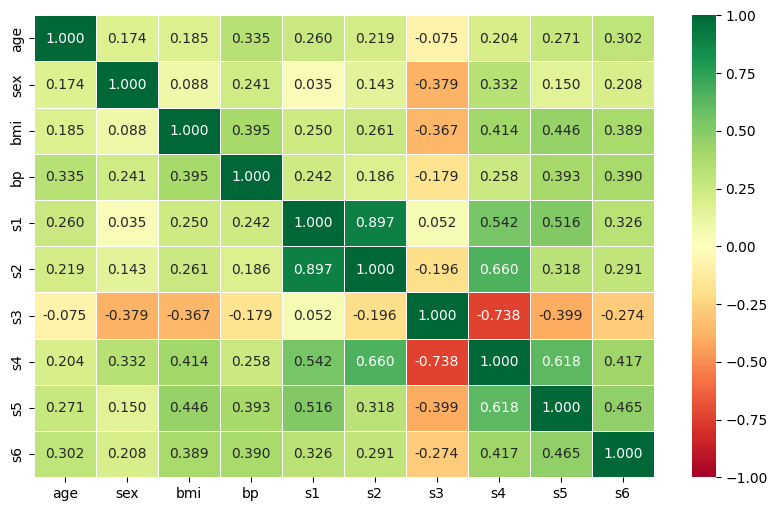

In [7]:
plt.subplots(figsize=(10, 6))

X_corr = X.corr()

sns.heatmap(
            X_corr,
            annot=True,
            fmt=".3f", 
            cmap='RdYlGn', 
            linewidth=.5, 
            vmin=-1, 
            vmax=1
);

In [8]:
# split data to 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 4.2 Base Model (Linear Regression without Regularization)

In [9]:
# 1. Initialize and fit the scaler on training features only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 2. Transform the test features using the already-fitted scaler
X_test_scaled = scaler.transform(X_test)

# 3. Initialize, fit, and predict with the Linear Regression model
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)

print(f'RMSE: {mean_squared_error(y_test,y_pred)**0.5}')  # complete code here
print(f'R2 Score: {r2_score(y_test,y_pred)}') # or lr.score(X_test_scaled, y_pred)

RMSE: 53.85344583676594
R2 Score: 0.45260276297191926


In [10]:
# Base Model Coefficient 
lr.coef_

array([  1.75375799, -11.51180908,  25.60712144,  16.82887167,
       -44.44885564,  24.64095356,   7.67697768,  13.1387839 ,
        35.16119521,   2.35136365])

### 4.3 Using `RidgeCV` and `LassoCV`

The difference between the standard models (`Ridge` / `Lasso`) and their **"CV"** counterparts (`RidgeCV` / `LassoCV`) comes down to manual vs. automatic **hyperparameter tuning**.

The **"CV" stands for Cross-Validation**. In Scikit-Learn, these CV classes are specially designed to find the **_best penalty strength (the alpha parameter)_** automatically, saving you from having to build a separate `GridSearchCV`.

**Here is the detailed breakdown of how they differ:**
1. **The Standard Models: `Ridge`, `Lasso` and `ElasticNet`**
When you use the standard `Ridge` or `Lasso` classes, **you must guess the penalty strength manually**. You provide a single value for the **alpha** parameter _(e.g., `alpha=1.0`)_. However, in the case of `ElasticNet` you would also need to guess the `l1_ratio` parameter. The model runs once, applies that exact penalty, and finishes. You will need to reiterate the process to find the best alpha manually, or you would have to wrap the model in a `GridSearchCV` and test them all yourself.
2. **The Auto-Tuning Models: `RidgeCV`, `LassoCV`and `ElasticNetCV`**
When you use `RidgeCV` or `LassoCV`, you are handing the model a list of possible penalty strengths (e.g., `alphas=[0.1, 1.0, 10.0]`). The model will automatically test all of them using cross-validation and pick the best one for you. In the case of `ElasticNetCV` you would also need to provide a list of possible `l1_ratio` values.

**RECAP - How the Cross-Validation Works:**
When you call `.fit()`, the model doesn't just evaluate the **alphas** once. It secretly divides your training data into multiple equal chunks (called "folds"). It trains on a few chunks and tests itself on the remaining chunk, rotating through until every piece of data has been used for validation. By averaging the errors across all these folds, it figures out which alpha produces the most consistently accurate results, and then trains its final self using that winning alpha.

>_**This built-in process is highly optimized, computing the best alpha significantly faster than if you used a standard `GridSearchCV`.**_

**Ridge Regression (L2 Regularization)**

In [11]:
# Alpha candidates
np.logspace(-3, 3, 100)

array([1.00000000e-03, 1.14975700e-03, 1.32194115e-03, 1.51991108e-03,
       1.74752840e-03, 2.00923300e-03, 2.31012970e-03, 2.65608778e-03,
       3.05385551e-03, 3.51119173e-03, 4.03701726e-03, 4.64158883e-03,
       5.33669923e-03, 6.13590727e-03, 7.05480231e-03, 8.11130831e-03,
       9.32603347e-03, 1.07226722e-02, 1.23284674e-02, 1.41747416e-02,
       1.62975083e-02, 1.87381742e-02, 2.15443469e-02, 2.47707636e-02,
       2.84803587e-02, 3.27454916e-02, 3.76493581e-02, 4.32876128e-02,
       4.97702356e-02, 5.72236766e-02, 6.57933225e-02, 7.56463328e-02,
       8.69749003e-02, 1.00000000e-01, 1.14975700e-01, 1.32194115e-01,
       1.51991108e-01, 1.74752840e-01, 2.00923300e-01, 2.31012970e-01,
       2.65608778e-01, 3.05385551e-01, 3.51119173e-01, 4.03701726e-01,
       4.64158883e-01, 5.33669923e-01, 6.13590727e-01, 7.05480231e-01,
       8.11130831e-01, 9.32603347e-01, 1.07226722e+00, 1.23284674e+00,
       1.41747416e+00, 1.62975083e+00, 1.87381742e+00, 2.15443469e+00,
      

In [12]:
from sklearn.linear_model import RidgeCV

# RidgeCV (L2) specify alpha ranges using np.logspace
alphas_val = np.logspace(-3, 3, 100) # Generates 100 values evenly spread between 0.001 and 1000 (10⁻³ to 10³)

# Cross-validate over our list of ridge alphas.
ridge_cv = RidgeCV(alphas=alphas_val, scoring='r2', cv=5)

# Fit model using best ridge alpha!
ridge_cv.fit(X_train_scaled, y_train)

RidgeCV(alphas=array([1.00000000e-03, 1.14975700e-03, 1.32194115e-03, 1.51991108e-03,
       1.74752840e-03, 2.00923300e-03, 2.31012970e-03, 2.65608778e-03,
       3.05385551e-03, 3.51119173e-03, 4.03701726e-03, 4.64158883e-03,
       5.33669923e-03, 6.13590727e-03, 7.05480231e-03, 8.11130831e-03,
       9.32603347e-03, 1.07226722e-02, 1.23284674e-02, 1.41747416e-02,
       1.62975083e-02, 1.87381742e-0...
       4.03701726e+01, 4.64158883e+01, 5.33669923e+01, 6.13590727e+01,
       7.05480231e+01, 8.11130831e+01, 9.32603347e+01, 1.07226722e+02,
       1.23284674e+02, 1.41747416e+02, 1.62975083e+02, 1.87381742e+02,
       2.15443469e+02, 2.47707636e+02, 2.84803587e+02, 3.27454916e+02,
       3.76493581e+02, 4.32876128e+02, 4.97702356e+02, 5.72236766e+02,
       6.57933225e+02, 7.56463328e+02, 8.69749003e+02, 1.00000000e+03]),
        cv=5, scoring='r2')

In [13]:
# Here is the optimal value of alpha
ridge_cv.alpha_

40.37017258596558

In [14]:
# Evaluate the model
y_pred_ridge = ridge_cv.predict(X_test_scaled)

print(f'RMSE: {mean_squared_error(y_test,y_pred_ridge)**0.5}')  # complete code here
print(f'R2 Score: {r2_score(y_test,y_pred_ridge)}') # or lr.score(X_test_scaled, y_pred)

RMSE: 53.46188407810228
R2 Score: 0.4605339399762022


In [15]:
# RidgeCV Coefficients
ridge_cv.coef_

array([ 2.0063465 , -9.89381768, 24.10541694, 15.366276  , -5.38421651,
       -4.05459995, -8.95853254,  7.23066179, 18.91682667,  3.76571762])

**Lasso Regression (L1 Regularization)**

In [16]:
from sklearn.linear_model import LassoCV

# Set up a list of Lasso alphas to check.
l_alphas = np.logspace(-3, 3, 100)

# Cross-validate over our list of Lasso alphas.
lasso_cv = LassoCV(alphas=l_alphas, cv=5)

# Fit model using best ridge alpha!
lasso_cv.fit(X_train_scaled, y_train);

In [17]:
# Here is the optimal value of alpha
lasso_cv.alpha_

1.629750834620645

In [18]:
# Evaluate the model
y_pred_lasso = lasso_cv.predict(X_test_scaled)

print(f'RMSE: {mean_squared_error(y_test,y_pred_lasso)**0.5}')  # complete code here
print(f'R2 Score: {r2_score(y_test,y_pred_lasso)}') # or lr.score(X_test_scaled, y_pred)

RMSE: 52.92133838246166
R2 Score: 0.47138772365756565


In [19]:
# LassoCV Coefficient 
lasso_cv.coef_

array([  0.        ,  -8.02142643,  26.18903241,  15.06441946,
        -4.86012346,  -0.        , -11.08667637,   0.        ,
        21.99612869,   1.75881184])

**ElasticNet (The Hybrid)**

ElasticNet combines both the **Lasso (L1)** and **Ridge (L2)** penalties into a single equation.
- It uses a hyperparameter (often called the `l1_ratio`__*__) to balance the behavior of Ridge and Lasso.
- Situations where you have a massive dataset with lots of correlated features, and you want the feature selection of Lasso without it randomly dropping correlated features too aggressively.
- It is the safest "best of both worlds" approach, but it requires more computational time to tune both the overall penalty strength and the L1/L2 ratio.

>__*__ The `l1_ratio` is a number that must fall strictly between 0.0 and 1.0. Here is how to think about the values:
>- __`l1_ratio = 0.0` (Pure Ridge):__ The model completely ignores the Lasso penalty. (Note: Scikit-Learn actually recommends just using the Ridge class if you want this, as it calculates faster!)
>- __`l1_ratio = 1.0` (Pure Lasso):__ The model completely ignores the Ridge penalty.
>- __`l1_ratio = 0.5` (50/50 Split):__ The model applies an equal mathematical penalty from both L1 and L2.

>By setting the l1_ratio to something high like 0.95, you are telling the model: __*"Act 95% like Lasso and drop the useless columns, but keep 5% of Ridge's behavior just to act as 'glue' to stabilize the highly correlated features."*__

In [21]:
from sklearn.linear_model import ElasticNetCV

#  Define parameter grids for ElasticNetCV
alphas_val = np.logspace(-5, 5, 100)
l1_ratio_val = np.linspace(0.1, 1, 10)

# Cross-validate over our list of Lasso alphas.
elastic_cv = ElasticNetCV(
                    alphas = l_alphas, 
                    l1_ratio= l1_ratio_val,
                    cv=5
                    )

# Fit model using best ridge alpha!
elastic_cv.fit(X_train_scaled, y_train)

ElasticNetCV(alphas=array([1.00000000e-03, 1.14975700e-03, 1.32194115e-03, 1.51991108e-03,
       1.74752840e-03, 2.00923300e-03, 2.31012970e-03, 2.65608778e-03,
       3.05385551e-03, 3.51119173e-03, 4.03701726e-03, 4.64158883e-03,
       5.33669923e-03, 6.13590727e-03, 7.05480231e-03, 8.11130831e-03,
       9.32603347e-03, 1.07226722e-02, 1.23284674e-02, 1.41747416e-02,
       1.62975083e-02, 1.873817...
       7.05480231e+01, 8.11130831e+01, 9.32603347e+01, 1.07226722e+02,
       1.23284674e+02, 1.41747416e+02, 1.62975083e+02, 1.87381742e+02,
       2.15443469e+02, 2.47707636e+02, 2.84803587e+02, 3.27454916e+02,
       3.76493581e+02, 4.32876128e+02, 4.97702356e+02, 5.72236766e+02,
       6.57933225e+02, 7.56463328e+02, 8.69749003e+02, 1.00000000e+03]),
             cv=5,
             l1_ratio=array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]))

In [22]:
# Here is the optimal value of alpha
elastic_cv.alpha_

0.11497569953977356

In [23]:
# Here is the optimal value of l1_ratio
elastic_cv.l1_ratio_

0.1

In [24]:
# Evaluate the model
y_pred_elastic = elastic_cv.predict(X_test_scaled)

print(f'RMSE: {mean_squared_error(y_test,y_pred_elastic)**0.5}')  # complete code here
print(f'R2 Score: {r2_score(y_test,y_pred_elastic)}') # or lr.score(X_test_scaled, y_pred)

RMSE: 53.469101976652006
R2 Score: 0.4603882633240788


**Regulariztion with Logistic Regression**

With logistic regression, regularization is built directly into `LogisticRegression`.

The main difference from Ridge/Lasso regression is that logistic regression uses `C`, where:
- Smaller `C` = stronger regularization
- Larger `C` = weaker regularization

In [11]:
# Data Creation
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000,
    n_features=200,
    n_informative=15,
    random_state=123
)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=123)

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [12]:
y_train[:10]

array([1, 1, 0, 0, 0, 1, 0, 1, 0, 0])

In [13]:
from sklearn.linear_model import LogisticRegression

# L2 regularization (Ridge-like)
lr_l2 = LogisticRegression(
                penalty="l2",
                C=1.0,
)

lr_l2.fit(X_train_sc, y_train)

LogisticRegression()

In [14]:
# L1 regularization (Lasso-like)
lr_l1 = LogisticRegression(
                penalty="l1",
                C=1.0,
                solver="liblinear"
)

lr_l1.fit(X_train_sc, y_train)

LogisticRegression(penalty='l1', solver='liblinear')

In [15]:
# Elastic
lr_en = LogisticRegression(
    penalty="elasticnet",
    C=1.0,
    l1_ratio=0.5,
    solver="saga"
)

lr_en.fit(X_train_sc, y_train)

LogisticRegression(l1_ratio=0.5, penalty='elasticnet', solver='saga')

In [16]:
# L2 regularization (Ridge-like) with cross validate

from sklearn.linear_model import LogisticRegressionCV


C_values = np.logspace(-3, 3, 100)

lr_cv = LogisticRegressionCV(
    Cs=C_values,
    penalty="l2",
    cv=5,
    scoring="f1"
)

lr_cv.fit(X_train_sc, y_train)

LogisticRegressionCV(Cs=array([1.00000000e-03, 1.14975700e-03, 1.32194115e-03, 1.51991108e-03,
       1.74752840e-03, 2.00923300e-03, 2.31012970e-03, 2.65608778e-03,
       3.05385551e-03, 3.51119173e-03, 4.03701726e-03, 4.64158883e-03,
       5.33669923e-03, 6.13590727e-03, 7.05480231e-03, 8.11130831e-03,
       9.32603347e-03, 1.07226722e-02, 1.23284674e-02, 1.41747416e-02,
       1.62975083e-02, 1.87...
       4.03701726e+01, 4.64158883e+01, 5.33669923e+01, 6.13590727e+01,
       7.05480231e+01, 8.11130831e+01, 9.32603347e+01, 1.07226722e+02,
       1.23284674e+02, 1.41747416e+02, 1.62975083e+02, 1.87381742e+02,
       2.15443469e+02, 2.47707636e+02, 2.84803587e+02, 3.27454916e+02,
       3.76493581e+02, 4.32876128e+02, 4.97702356e+02, 5.72236766e+02,
       6.57933225e+02, 7.56463328e+02, 8.69749003e+02, 1.00000000e+03]),
                     cv=5, scoring='f1')

In [17]:
lr_cv.C_

array([0.01873817])

## Wrap-Up:

It is completely normal to feel overwhelmed by all these different models and acronyms! The most important thing to remember as a data scientist is this: **You do not need to magically know the perfect model before you start.** Machine learning is about conducting controlled experiments. You start with a simple baseline model. If it overfits, you run a new experiment adding a "penalty" (regularization). You observe the results, tweak the approach, and see what works best for your specific data.

Here is your conceptual guide for setting up those experiments.

### The "Which Approach Do I Choose?" Guide

When deciding which regularization experiment to run, think about what you want to do with your dataset's columns (features):

* **Ridge (L2):** Choose this when you believe all features contribute a small, real effect to the prediction, or when features are highly correlated. Instead of throwing columns away, Ridge evenly shrinks all coefficient weights to stabilize the model and combat multicollinearity. It serves as your safest, most reliable baseline experiment.
* **Lasso (L1):** Choose this when you have a high-dimensional dataset (many columns) and suspect a significant portion of them are irrelevant noise. Lasso acts as a built-in feature selector—its absolute penalty geometry ruthlessly forces the weights of non-predictive variables to exactly zero, generating a clean, highly interpretable sparse model (most of the coefficient weights are set exactly to zero)
* **ElasticNet:** Choose this when you are dealing with a complex, high-dimensional dataset containing many highly correlated features. ElasticNet combines the strengths of both worlds—it leverages Lasso (L1) to ruthlessly eliminate completely useless noise, while utilizing Ridge (L2) to ensure that correlated variables share weight and stabilize the model rather than being arbitrarily deleted.

### Watch Out For:

No matter which experiment you run, if you forget these three rules, your results will be invalid:

1. **You Must Scale Your Data:** Regularization is obsessed with the size of your numbers. If you do not put your data through a `StandardScaler`, a column with large numbers (like Income = $80,000) will be penalized much harder than a column with small numbers (like Age = 25).
3. **Opposite Dials (`alpha` vs. `C`):**
    * When running **Regression** (Ridge/Lasso), the penalty dial is called **`alpha`**. Turning it *up* makes the penalty stronger.
    * When running **Classification** (Logistic Regression), the penalty dial is called **`C`**. Turning it *down* makes the penalty stronger.